# Probabilidades sorteadas para cada AST: cobertura dos suportes canônicos

**Pergunta:** variar as probabilidades fornecidas ao gerador para cada árvore aumenta a variedade de suportes polinomiais canônicos? O experimento compara 50.000 árvores com a configuração fixa do [notebook 2](../2_random_ast_distribution.ipynb) e 50.000 árvores com probabilidades sorteadas. As duas condições usam os mesmos índices e seeds para as ASTs; o sorteio das probabilidades usa uma sequência separada. A estrutura da árvore continua sendo produzida por `sample_random_mechanism`.

Aqui, um **suporte** é a lista ordenada dos monômios com coeficiente realizado diferente de zero. A fórmula `1 + x_0(t-6)` indica a presença de uma constante e do lag 6, com os coeficientes omitidos. Esta análise avalia o sorteador polinomial geral com uma série e lags 1–12.

## 1. Duas condi??es compar?veis

A condi??o fixa usa $p_{\mathrm{par?metro}}=0{,}40$, $p_{\mathrm{lag}}=0{,}60$ e $p_{\mathrm{soma}}=0{,}65$. Na condi??o vari?vel, para **cada ?rvore** sorteamos independentemente
$p_{\mathrm{par?metro}}\sim\mathcal{U}(0,1)$ e
$p_{\mathrm{soma}}\sim\mathcal{U}(0,1)$; definimos
$p_{\mathrm{lag}}=1-p_{\mathrm{par?metro}}$ e
$p_{\mathrm{produto}}=1-p_{\mathrm{soma}}$.
Assim, as probabilidades m?dias de par?metro e soma passam a 0,50. Dentro de uma ?rvore, todas as folhas compartilham o mesmo par de probabilidades e todos os operadores compartilham a mesma probabilidade de soma. O n?mero de operadores, os lags admiss?veis, os limites dos par?metros e a exig?ncia de pelo menos um lag permanecem iguais.

In [1]:
from collections import Counter
from dataclasses import replace
from math import comb, exp, log
from pathlib import Path
from time import perf_counter
import platform
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'pyproject.toml').exists() and (p / 'src/tsfmxai').exists())
sys.path.insert(0, str(ROOT / 'src'))
from tsfmxai.generators import (
    RandomTreeConfig, derive_sample_seed, sample_random_mechanism,
)
from tsfmxai.representations import Lag, canonicalize_polynomial, walk

ROOT_SEED = 20261028
SAMPLE_COUNT = 50_000
CHECKPOINTS = (100, 500, 1_000, 5_000, 10_000, 20_000, 50_000)
MAX_DEGREE = 4
TOP_N = 15
BASE = RandomTreeConfig()
assert BASE.num_series == 1 and BASE.minimum_lag == 1 and BASE.maximum_lag == 12
assert (BASE.parameter_probability, BASE.lag_probability, BASE.add_probability) == (.4, .6, .65)
LAG_COUNT = BASE.maximum_lag - BASE.minimum_lag + 1
POSSIBLE_MONOMIALS = comb(LAG_COUNT + MAX_DEGREE, MAX_DEGREE)
assert POSSIBLE_MONOMIALS == 1820
print('Base:', BASE)
print('Seed raiz:', ROOT_SEED, '| sorteios por condição:', SAMPLE_COUNT)

Base: RandomTreeConfig(minimum_operators=1, maximum_operators=6, num_series=1, minimum_lag=1, maximum_lag=12, parameter_probability=0.4, lag_probability=0.6, add_probability=0.65, minimum_parameter_magnitude=0.05, maximum_parameter_magnitude=0.9, require_lag=True, coefficient_gate_lags=False)
Seed raiz: 20261028 | sorteios por condição: 50000


**O que foi feito:** definimos uma comparação pareada, o vocabulário e os mesmos limites usados na análise anterior. A seed raiz é registrada e cada índice produz uma seed local estável.

In [2]:
def probabilities_for_index(index):
    probability_seed = np.random.SeedSequence(
        [ROOT_SEED, index, 20261028]
    ).generate_state(1, dtype=np.uint64)[0]
    rng = np.random.default_rng(int(probability_seed))
    p_parameter = float(rng.uniform(0.0, 1.0))
    p_add = float(rng.uniform(0.0, 1.0))
    return p_parameter, 1. - p_parameter, p_add

probability_rows = np.asarray(
    [probabilities_for_index(index) for index in range(SAMPLE_COUNT)]
)
assert np.all((0 < probability_rows) & (probability_rows < 1))
assert np.allclose(probability_rows[:, 0] + probability_rows[:, 1], 1.)
assert probabilities_for_index(8) == probabilities_for_index(8)
probability_df = pd.DataFrame(
    probability_rows, columns=['Parâmetro', 'Lag', 'Soma']
)
display(probability_df.describe(percentiles=[.05, .5, .95]).round(3))

,Parâmetro,Lag,Soma
count,50000.000,50000.000,50000.000
mean,0.502,0.498,0.499
std,0.288,0.288,0.290
min,0.000,0.000,0.000
5%,0.051,0.050,0.049
50%,0.503,0.497,0.499
95%,0.950,0.949,0.950
max,1.000,1.000,1.000


**O que foi feito:** sorteamos um conjunto independente de probabilidades uniformes por ?rvore. A tabela mostra a dispers?o realizada e permite conferir as m?dias pr?ximas de 0,50.

In [3]:
METHODS = ('Fixa', 'Probabilidades sorteadas')
def new_stats():
    return {
        'supports': Counter(), 'lag_leaves': Counter(),
        'lag_presence': Counter(), 'monomials': {degree: set() for degree in range(5)},
        'degree_tree_count': Counter(), 'accepted': 0, 'degree_rejected': 0,
        'sample_seconds': 0., 'canonical_seconds': 0.,
    }

stats = {method: new_stats() for method in METHODS}
checkpoints = []
for index in range(SAMPLE_COUNT):
    tree_seed = derive_sample_seed(ROOT_SEED, index)
    p_parameter, p_lag, p_add = probability_rows[index]
    configs = {
        'Fixa': BASE,
        'Probabilidades sorteadas': replace(
            BASE, parameter_probability=float(p_parameter),
            lag_probability=float(p_lag), add_probability=float(p_add),
        ),
    }
    for method in METHODS:
        st = stats[method]
        started = perf_counter()
        mechanism = sample_random_mechanism(
            configs[method], seed=tree_seed, sample_index=index,
        )
        st['sample_seconds'] += perf_counter() - started
        for node in walk(mechanism.expression):
            if isinstance(node, Lag):
                st['lag_leaves'][mechanism.binding.lag_values[node.slot]] += 1
        started = perf_counter()
        try:
            normal = canonicalize_polynomial(
                mechanism.expression, mechanism.binding, max_degree=MAX_DEGREE,
            )
        except ValueError as error:
            assert 'degree' in str(error), (method, index, str(error))
            st['degree_rejected'] += 1
        else:
            st['accepted'] += 1
            st['supports'][normal.skeleton] += 1
            degrees, present_lags = set(), set()
            for term in normal.skeleton:
                degree = len(term)
                degrees.add(degree)
                st['monomials'][degree].add(term)
                present_lags.update(lag for _, lag in term)
            st['degree_tree_count'].update(degrees)
            st['lag_presence'].update(present_lags)
        st['canonical_seconds'] += perf_counter() - started
    if index + 1 in CHECKPOINTS:
        for method in METHODS:
            st = stats[method]
            checkpoints.append({
                'Método': method, 'Gerações': index + 1,
                'Convertidas': st['accepted'],
                'Rejeitadas por grau': st['degree_rejected'],
                'Suportes distintos': len(st['supports']),
                'Lags presentes': sum(st['lag_presence'][lag] > 0
                                     for lag in range(1, 13)),
            })

for method in METHODS:
    st = stats[method]
    assert st['accepted'] + st['degree_rejected'] == SAMPLE_COUNT
    assert sum(st['supports'].values()) == st['accepted']
coverage_df = pd.DataFrame(checkpoints)
display(coverage_df)

,Método,Gerações,Convertidas,Rejeitadas por grau,Suportes distintos,Lags presentes
0,Fixa,100,100,0,92,12
1,Probabilidades sorteadas,100,98,2,77,12
2,Fixa,500,497,3,376,12
3,Probabilidades sorteadas,500,484,16,266,12
4,Fixa,1000,997,3,679,12
5,Probabilidades sorteadas,1000,965,35,492,12
6,Fixa,5000,4986,14,2606,12
7,Probabilidades sorteadas,5000,4812,188,1926,12
8,Fixa,10000,9971,29,4646,12
9,Probabilidades sorteadas,10000,9633,367,3428,12


**O que foi feito:** para cada índice, usamos a mesma seed de AST nas duas condições e seeds separadas para sortear as probabilidades. Cada árvore foi expandida e convertida em suporte; rejeições de grau ficaram registradas. A tabela acompanha a diversidade ao longo dos mesmos prefixos de gerações.

In [4]:
def effective_diversity(counts):
    total = sum(counts.values())
    return exp(-sum((count/total) * log(count/total)
                    for count in counts.values()))

summary_rows, factor_rows, lag_rows = [], [], []
for method in METHODS:
    st = stats[method]
    top_fifteen = sum(count for _, count in st['supports'].most_common(TOP_N))
    summary_rows.append({
        'Método': method, 'Convertidas': st['accepted'],
        'Rejeitadas por grau': st['degree_rejected'],
        'Suportes distintos': len(st['supports']),
        'Suportes que aparecem uma vez': sum(
            count == 1 for count in st['supports'].values()),
        'Diversidade efetiva (exp entropia)': effective_diversity(st['supports']),
        'Top 15 entre convertidas (%)': 100 * top_fifteen / st['accepted'],
        'Amostragem (s)': st['sample_seconds'],
        'Canonização (s)': st['canonical_seconds'],
        'Convertidas/s, tempo medido': st['accepted'] / (
            st['sample_seconds'] + st['canonical_seconds']),
    })
    for lag in range(1, LAG_COUNT + 1):
        lag_rows.append({
            'Método': method, 'Lag': lag,
            'Folhas sorteadas': st['lag_leaves'][lag],
            'Convertidas que usam o lag': st['lag_presence'][lag],
            'Convertidas que usam o lag (%)':
                100 * st['lag_presence'][lag] / st['accepted'],
        })
    for degree in range(MAX_DEGREE + 1):
        possible = comb(LAG_COUNT + degree - 1, degree) if degree else 1
        observed = len(st['monomials'][degree])
        factor_rows.append({
            'Método': method, 'Fatores por termo': degree,
            'Monômios possíveis': possible,
            'Monômios observados': observed,
            'Cobertura (%)': 100 * observed / possible,
            'Convertidas com esse grau': st['degree_tree_count'][degree],
        })
summary_df = pd.DataFrame(summary_rows)
factor_df = pd.DataFrame(factor_rows)
lag_df = pd.DataFrame(lag_rows)
display(summary_df.round(3))
display(factor_df.round(2))
display(lag_df.round(2))
assert factor_df.groupby('Método')['Monômios possíveis'].sum().eq(POSSIBLE_MONOMIALS).all()

,Método,Convertidas,Rejeitadas por grau,Suportes distintos,Suportes que aparecem uma vez,Diversidade efetiva (exp entropia),Top 15 entre convertidas (%),Amostragem (s),Canonização (s),"Convertidas/s, tempo medido"
0,Fixa,49838,162,17101,13827,2861.559,19.134,15.650,4.750,2443.010
1,Probabilidades sorteadas,48157,1843,12141,9537,969.529,31.474,15.888,4.425,2370.759


,Método,Fatores por termo,Monômios possíveis,Monômios observados,Cobertura (%),Convertidas com esse grau
0,Fixa,0,1,1,100.00,26009
1,Fixa,1,12,12,100.00,41977
2,Fixa,2,78,78,100.00,19615
3,Fixa,3,364,364,100.00,5749
4,Fixa,4,1365,811,59.41,1041
5,Probabilidades sorteadas,0,1,1,100.00,21357
6,Probabilidades sorteadas,1,12,12,100.00,37357
7,Probabilidades sorteadas,2,78,78,100.00,12457
8,Probabilidades sorteadas,3,364,364,100.00,5621
9,Probabilidades sorteadas,4,1365,1141,83.59,2488


,Método,Lag,Folhas sorteadas,Convertidas que usam o lag,Convertidas que usam o lag (%)
0,Fixa,1,11351,10245,20.56
1,Fixa,2,11525,10367,20.80
2,Fixa,3,11587,10387,20.84
3,Fixa,4,11555,10350,20.77
4,Fixa,5,11604,10453,20.97
5,Fixa,6,11614,10423,20.91
6,Fixa,7,11337,10202,20.47
7,Fixa,8,11190,10106,20.28
8,Fixa,9,11563,10334,20.74
9,Fixa,10,11443,10288,20.64


**O que foi feito:** a primeira tabela reúne diversidade, concentração e custo medido. As seguintes mostram a cobertura dos 12 lags e de monômios com zero a quatro fatores. Diversidade efetiva é `exp(entropia)` das frequências dos suportes: ela diminui quando poucos padrões dominam.

In [5]:
def support_formula(support):
    if not support:
        return '0'
    terms = []
    for monomial in support:
        if not monomial:
            terms.append('1')
            continue
        multiplicities = Counter(monomial)
        terms.append(' × '.join(
            f'x_{series}(t-{lag})' + (f'^{power}' if power > 1 else '')
            for (series, lag), power in sorted(multiplicities.items())
        ))
    return ' + '.join(terms)

top_rows = []
for method in METHODS:
    st = stats[method]
    ranked = sorted(st['supports'].items(), key=lambda item: (-item[1], item[0]))
    for rank, (support, count) in enumerate(ranked[:TOP_N], start=1):
        top_rows.append({
            'Método': method, 'Posição': rank,
            'Fórmula do suporte (sem coeficientes)': support_formula(support),
            'Convertidas': count,
            'Frequência entre convertidas (%)': 100 * count / st['accepted'],
        })
top_df = pd.DataFrame(top_rows)
display(top_df.round(3))

,Método,Posição,Fórmula do suporte (sem coeficientes),Convertidas,Frequência entre convertidas (%)
0,Fixa,1,1 + x_0(t-6),780,1.565
1,Fixa,2,1 + x_0(t-4),761,1.527
2,Fixa,3,1 + x_0(t-10),754,1.513
3,Fixa,4,1 + x_0(t-5),734,1.473
4,Fixa,5,1 + x_0(t-3),732,1.469
5,Fixa,6,1 + x_0(t-11),732,1.469
6,Fixa,7,1 + x_0(t-12),728,1.461
7,Fixa,8,1 + x_0(t-1),715,1.435
8,Fixa,9,1 + x_0(t-2),709,1.423
9,Fixa,10,1 + x_0(t-9),709,1.423


**O que foi feito:** listamos as fórmulas dos 15 suportes mais frequentes em cada condição. A contagem considera árvores convertidas; coeficientes diferentes compartilham o mesmo suporte.

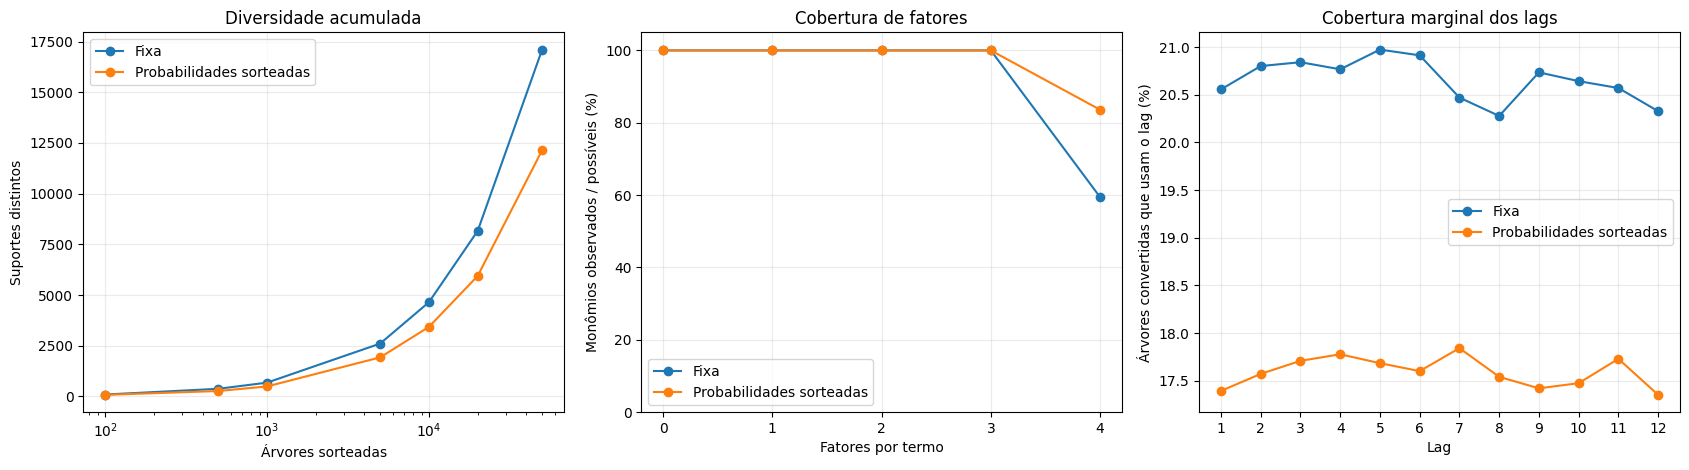

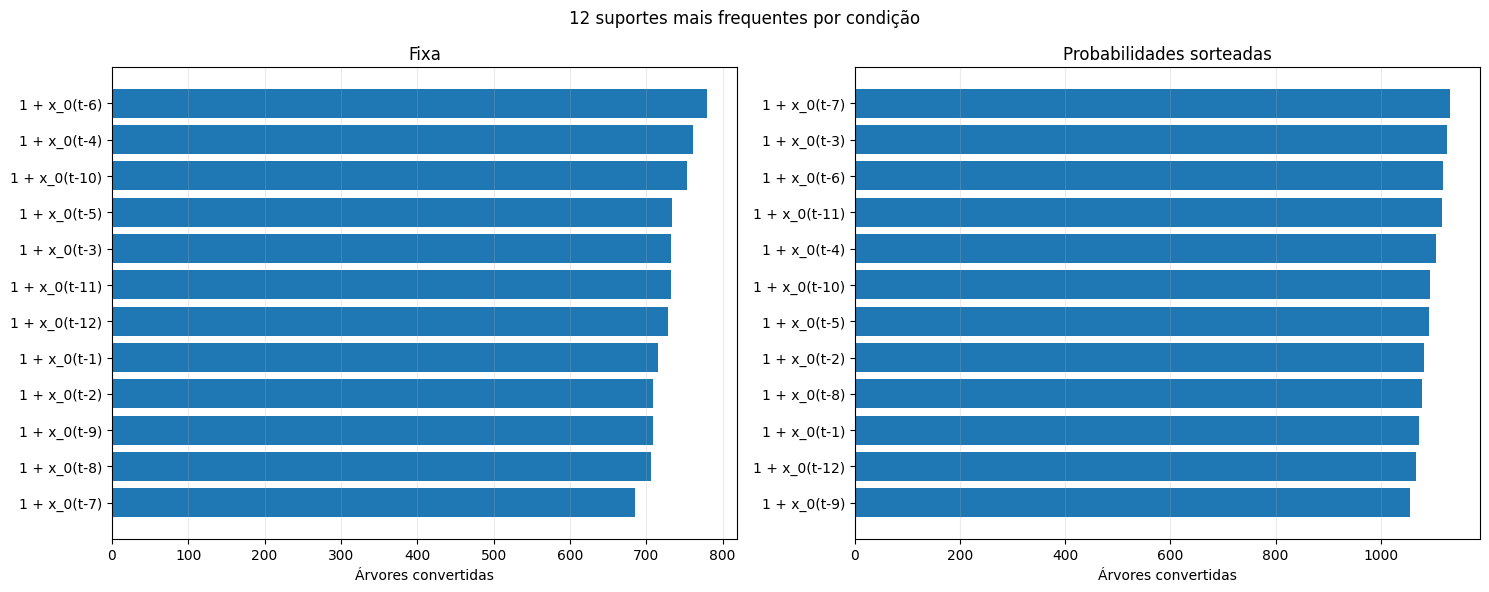

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for method in METHODS:
    part = coverage_df[coverage_df['Método'].eq(method)]
    axes[0].plot(part['Gerações'], part['Suportes distintos'], marker='o', label=method)
axes[0].set(xscale='log', xlabel='Árvores sorteadas', ylabel='Suportes distintos',
            title='Diversidade acumulada')
axes[0].legend()
for method in METHODS:
    part = factor_df[factor_df['Método'].eq(method)]
    axes[1].plot(part['Fatores por termo'], part['Cobertura (%)'], marker='o', label=method)
axes[1].set(xlabel='Fatores por termo', ylabel='Monômios observados / possíveis (%)',
            title='Cobertura de fatores', ylim=(0, 105))
axes[1].set_xticks(range(5))
axes[1].legend()
for method in METHODS:
    part = lag_df[lag_df['Método'].eq(method)]
    axes[2].plot(part['Lag'], part['Convertidas que usam o lag (%)'],
                 marker='o', label=method)
axes[2].set(xlabel='Lag', ylabel='Árvores convertidas que usam o lag (%)',
            title='Cobertura marginal dos lags')
axes[2].set_xticks(range(1, 13))
axes[2].legend()
for ax in axes: ax.grid(alpha=.25)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, method in zip(axes, METHODS):
    part = top_df[top_df['Método'].eq(method)].head(12).iloc[::-1]
    ax.barh(part['Fórmula do suporte (sem coeficientes)'], part['Convertidas'])
    ax.set(xlabel='Árvores convertidas', title=method)
    ax.grid(axis='x', alpha=.25)
fig.suptitle('12 suportes mais frequentes por condição')
fig.tight_layout()
plt.show()

**O que foi feito:** os gráficos comparam descoberta acumulada, cobertura por grau, presença de cada lag e as fórmulas mais frequentes. As escalas e denominadores são iguais entre as condições.

In [7]:
base_row, mixed_row = summary_df.set_index('Método').loc[list(METHODS)].to_dict('records')
delta = mixed_row['Suportes distintos'] - base_row['Suportes distintos']
relative = 100 * delta / base_row['Suportes distintos']
base_degree4 = factor_df.query("Método == 'Fixa' and `Fatores por termo` == 4").iloc[0]
mixed_degree4 = factor_df.query("Método == 'Probabilidades sorteadas' and `Fatores por termo` == 4").iloc[0]
print(f'Diferença em suportes distintos: {delta:+d} ({relative:+.2f}%).')
print('Cobertura de grau 4: %.2f%% -> %.2f%%' %
      (base_degree4['Cobertura (%)'], mixed_degree4['Cobertura (%)']))
print('A comparação mede a prior resultante do sorteio de probabilidades por árvore.')

Diferença em suportes distintos: -4960 (-29.00%).
Cobertura de grau 4: 59.41% -> 83.59%
A comparação mede a prior resultante do sorteio de probabilidades por árvore.


**O que foi feito:** sintetizamos o efeito observado na diversidade e na cobertura dos produtos de quatro fatores, mantendo explícita a configuração que produziu o resultado.

In [8]:
# Registro completo do experimento executado
record = {
    'pergunta': 'Sortear as probabilidades da AST por árvore melhora a cobertura de suportes canônicos?',
    'hipotese': 'A variação das probabilidades pode produzir suportes mais diversos com as mesmas médias marginais.',
    'configuracao_completa': {
        'base_config': BASE.__dict__, 'conditions': METHODS,
        'sample_count_per_condition': SAMPLE_COUNT, 'checkpoints': CHECKPOINTS,
        'probability_prior': {
            'parameter': 'Uniform(0, 1)', 'lag': '1 - p_parameter',
            'addition': 'Uniform(0, 1)', 'multiplication': '1 - p_add',
            'draws_per_tree': True, 'max_polynomial_degree': MAX_DEGREE,
        },
        'top_supports_reported': TOP_N,
    },
    'proveniencia': {
        'notebook': 'experiments/canonicalization/randomized_probabilities/1_randomized_probability_coverage.ipynb',
        'sampler': 'src/tsfmxai/generators/random_expression.py',
        'canonicalizer': 'src/tsfmxai/representations/canonical_polynomial.py',
        'randomness': 'tree_seed=derive_sample_seed(root_seed,index); probability_seed=SeedSequence([root_seed,index,20261028])',
        'root_seed': ROOT_SEED, 'sample_indices': [0, SAMPLE_COUNT - 1],
        'python': platform.python_version(), 'numpy': np.__version__,
        'pandas': pd.__version__, 'matplotlib': matplotlib.__version__,
        'hardware': 'CPU', 'external_data': None,
    },
    'metricas': {
        'probability_summary': probability_df.describe(percentiles=[.05,.5,.95]).to_dict(),
        'summary': summary_df.to_dict(orient='records'),
        'checkpoints': coverage_df.to_dict(orient='records'),
        'lag_coverage': lag_df.to_dict(orient='records'),
        'factor_coverage': factor_df.to_dict(orient='records'),
        'top_supports': top_df.to_dict(orient='records'),
        'possible_monomials': POSSIBLE_MONOMIALS,
    },
    'resumo_cientifico': (
        f"Com {SAMPLE_COUNT} ASTs por condição, a base produziu {base_row['Suportes distintos']} "
        f"suportes e as probabilidades sorteadas produziram {mixed_row['Suportes distintos']}; "
        f"diferença de {delta:+d} ({relative:+.2f}%). "
        f"O grau 4 cobriu {base_degree4['Cobertura (%)']:.2f}% e "
        f"{mixed_degree4['Cobertura (%)']:.2f}%, respectivamente. "
        'O resultado descreve esta prior e seed, não toda distribuição de probabilidades possível.'
    ),
    'reproducao': (
        'A partir da raiz: .venv\\Scripts\\python.exe -m jupyter nbconvert '
        '--to notebook --execute --inplace '
        'experiments/canonicalization/randomized_probabilities/'
        '1_randomized_probability_coverage.ipynb'
    ),
}
from pprint import pprint
pprint(record, sort_dicts=False)

{'pergunta': 'Sortear as probabilidades da AST por árvore melhora a cobertura '
             'de suportes canônicos?',
 'hipotese': 'A variação das probabilidades pode produzir suportes mais '
             'diversos com as mesmas médias marginais.',
 'configuracao_completa': {'base_config': {'minimum_operators': 1,
                                           'maximum_operators': 6,
                                           'num_series': 1,
                                           'minimum_lag': 1,
                                           'maximum_lag': 12,
                                           'parameter_probability': 0.4,
                                           'lag_probability': 0.6,
                                           'add_probability': 0.65,
                                           'minimum_parameter_magnitude': 0.05,
                                           'maximum_parameter_magnitude': 0.9,
                                           'require_lag': True,
  